# Heart Disease Data Analysis

**Group 7 | Data Analytics (CES2103) | III semester B.Tech. CSE | Section I**

**Problem statement:** To analyse how patient attributes are associated with heart disease using exploratory data analysis and statistical tests.

**Team:** Spandan Shetty, Adarsh S P, Siddharth Hari.

The supplied CSV contains 918 patient records and the binary `HeartDisease` label. The label does not specifically identify heart attacks. This analysis describes associations, which do not establish causes.


## 1. Load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, ttest_ind

from IPython.display import display

sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams.update({'figure.figsize': (7, 4), 'figure.dpi': 120})

df = pd.read_csv('heart.csv')
print('Shape:', df.shape)
display(df.head())

Shape: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### Column guide

| Column | Meaning |
|---|---|
| `Age`, `Sex` | Age in years; F = female, M = male |
| `ChestPainType` | TA = typical angina, ATA = atypical angina, NAP = non-anginal pain, ASY = asymptomatic |
| `RestingBP`, `Cholesterol` | Resting blood pressure (mm Hg); serum cholesterol (mg/dL) |
| `FastingBS`, `RestingECG` | Fasting blood sugar above 120 mg/dL (1 = yes); resting ECG category (Normal, ST, LVH) |
| `MaxHR`, `ExerciseAngina` | Maximum heart rate; exercise-induced angina (Y = yes, N = no) |
| `Oldpeak`, `ST_Slope` | ST depression during exercise relative to rest; exercise ST-segment slope (Up, Flat, Down) |
| `HeartDisease` | Dataset outcome label: 0 = no heart disease, 1 = heart disease |

These are the dataset's recorded categories, not diagnoses made by this notebook.

## 2. Check and clean the data

There are no blank cells, but zero blood pressure and cholesterol readings are not usable measurements. We fill the one zero `RestingBP` value with the median of the nonzero readings. We mark the 172 zero `Cholesterol` values as missing (`NaN`) and keep those rows. The cholesterol plot uses only measured readings; no hypothesis test compares cholesterol measurements. The raw CSV remains unchanged.

In [2]:
print('Missing values before cleaning:')
print(df.isna().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Zero RestingBP:', (df['RestingBP'] == 0).sum())
print('Zero Cholesterol:', (df['Cholesterol'] == 0).sum())

data = df.copy()
data['RestingBP'] = data['RestingBP'].replace(0, np.nan)
data['Cholesterol'] = data['Cholesterol'].replace(0, np.nan)
bp_median = data['RestingBP'].median()
data['RestingBP'] = data['RestingBP'].fillna(bp_median)
print('RestingBP replacement median:', bp_median)
print('Cholesterol missing after cleaning:', data['Cholesterol'].isna().sum())
print('Cholesterol missing by heart-disease label:')
display(pd.crosstab(data['HeartDisease'], data['Cholesterol'].isna(),
                    rownames=['HeartDisease'], colnames=['Cholesterol missing']))

Missing values before cleaning:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64
Duplicate rows: 0
Zero RestingBP: 1
Zero Cholesterol: 172
RestingBP replacement median: 130.0
Cholesterol missing after cleaning: 172
Cholesterol missing by heart-disease label:


Cholesterol missing,False,True
HeartDisease,,
0,390,20
1,356,152


The missing cholesterol readings are more common in the `HeartDisease = 1` group. Filling cholesterol separately using each outcome group would use the answer to construct the data, so we do not do that. We also do not make a conclusion about cholesterol from the measured subset alone.

### Additional data checks

We also check the data types and look for unusually high or low values with the 1.5 x IQR rule. A value outside these fences is not automatically an error, so a value is only changed when it is impossible (such as a blood pressure of 0).

In [3]:
print('Column types and number of distinct values:')
display(pd.DataFrame({'dtype': data.dtypes.astype(str), 'distinct values': data.nunique()}))

rows = []
for column in ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']:
    q1, q3 = data[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append([column, int((data[column] < low).sum()), int((data[column] > high).sum())])
outliers = pd.DataFrame(rows, columns=['Column', 'Below lower fence', 'Above upper fence'])
print()
print('Values outside the 1.5 x IQR fences (cholesterol: measured readings only):')
display(outliers)
print('Negative Oldpeak values:', int((data['Oldpeak'] < 0).sum()))

cleaning_summary = pd.DataFrame([
    ['Blank cells', 'None found', int(df.isna().sum().sum())],
    ['Duplicate rows', 'None found', int(df.duplicated().sum())],
    ['RestingBP = 0 (impossible)', 'Replaced with median of nonzero readings', int((df['RestingBP'] == 0).sum())],
    ['Cholesterol = 0 (impossible)', 'Set to missing (NaN); rows kept', int((df['Cholesterol'] == 0).sum())],
    ['Unusual but possible values (IQR rule)', 'Kept as recorded', int(outliers[['Below lower fence', 'Above upper fence']].sum().sum())],
], columns=['Issue', 'Action', 'Values affected'])
print()
print('Preprocessing summary:')
display(cleaning_summary)

Column types and number of distinct values:


,dtype,distinct values
Age,int64,50
Sex,str,2
ChestPainType,str,4
RestingBP,float64,66
Cholesterol,float64,221
FastingBS,int64,2
RestingECG,str,3
MaxHR,int64,119
ExerciseAngina,str,2
Oldpeak,float64,53



Values outside the 1.5 x IQR fences (cholesterol: measured readings only):


,Column,Below lower fence,Above upper fence
0,Age,0,0
1,RestingBP,1,26
2,Cholesterol,3,20
3,MaxHR,2,0
4,Oldpeak,1,15


Negative Oldpeak values: 13

Preprocessing summary:


,Issue,Action,Values affected
0,Blank cells,None found,0
1,Duplicate rows,None found,0
2,RestingBP = 0 (impossible),Replaced with median of nonzero readings,1
3,Cholesterol = 0 (impossible),Set to missing (NaN); rows kept,172
4,Unusual but possible values (IQR rule),Kept as recorded,68


The IQR rule flags 68 values across the five screened columns; this is a count of values, not necessarily distinct records. We retain them because the fence alone does not establish a recording error. We also retain the 13 negative `Oldpeak` values because their validity cannot be resolved from this CSV alone. The table above documents the cleaning decisions.


## 3. Exploratory data analysis (EDA)

First, see how many records belong to each target class.

HeartDisease
0    410
1    508
Name: count, dtype: int64


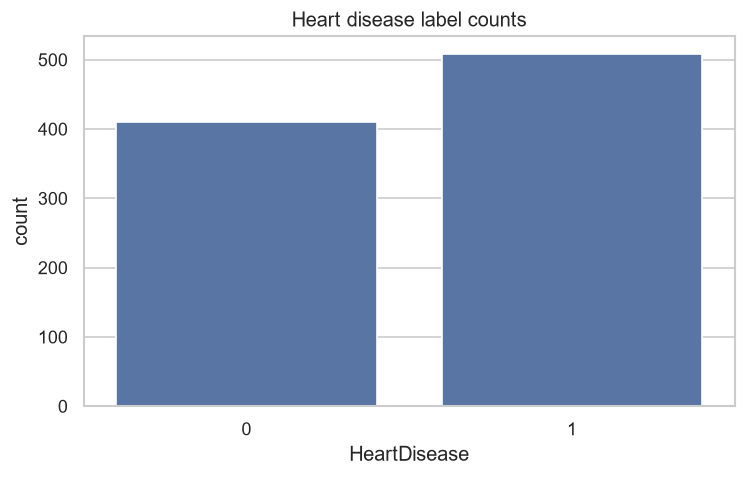

In [4]:
print(data['HeartDisease'].value_counts().sort_index())
sns.countplot(data=data, x='HeartDisease')
plt.title('Heart disease label counts')
plt.show()

### Cholesterol: missing readings and measured values

First check how often cholesterol is missing in each outcome group. Then compare only the recorded readings. The medians describe the measured subset; they do not tell us the missing readings.

Cholesterol missing (%) by label:


HeartDisease
0     4.9
1    29.9
Name: Cholesterol, dtype: float64

Recorded cholesterol values by label:


,count,mean,median
HeartDisease,,,
0,390,238.8,231.5
1,356,251.1,246.0


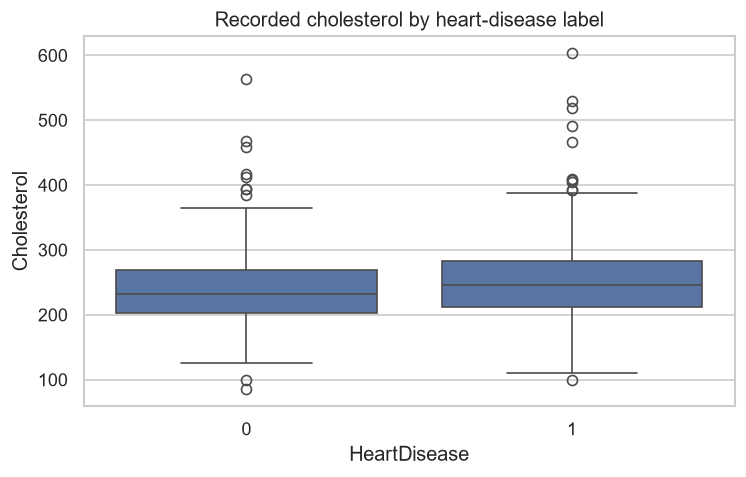

In [5]:
missing_rate = data.groupby('HeartDisease')['Cholesterol'].apply(
    lambda values: values.isna().mean() * 100
)
print('Cholesterol missing (%) by label:')
display(missing_rate.round(1))

measured = data.dropna(subset=['Cholesterol'])
print('Recorded cholesterol values by label:')
display(measured.groupby('HeartDisease')['Cholesterol'].agg(
    ['count', 'mean', 'median']
).round(1))

sns.boxplot(data=measured, x='HeartDisease', y='Cholesterol')
plt.title('Recorded cholesterol by heart-disease label')
plt.show()

In the measured subset, the median cholesterol is 231.5 for label 0 and 246 for label 1. However, cholesterol is missing in 4.9% of label 0 and 29.9% of label 1 records. Since missingness differs so much, this comparison should not be treated as a reliable conclusion about cholesterol for all 918 records. We do not test cholesterol measurements; Section 4.2 tests whether their missingness is associated with the outcome.

Compare age, maximum heart rate and Oldpeak between the two outcome groups.

                Age   MaxHR  Oldpeak
HeartDisease                        
0             50.55  148.15     0.41
1             55.90  127.66     1.27


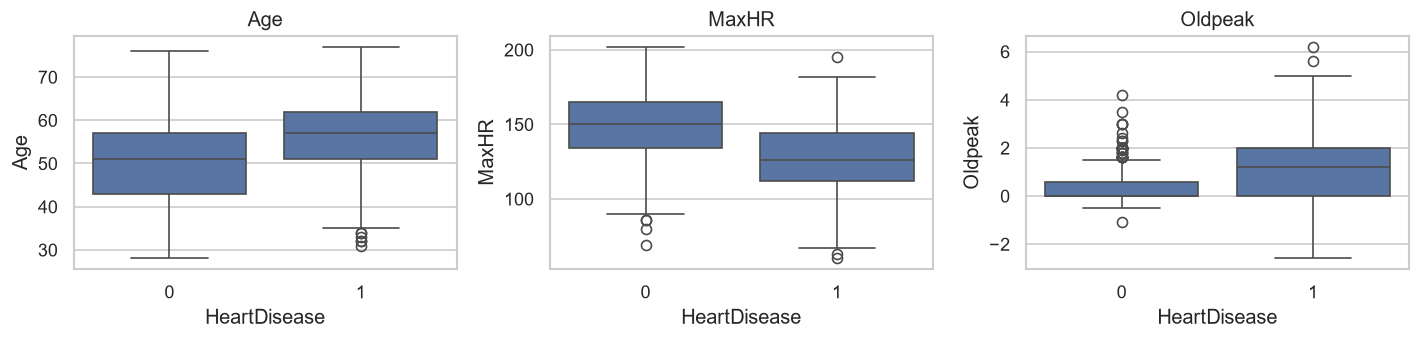

In [6]:
print(data.groupby('HeartDisease')[['Age', 'MaxHR', 'Oldpeak']].mean().round(2))
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, column in zip(axes, ['Age', 'MaxHR', 'Oldpeak']):
    sns.boxplot(data=data, x='HeartDisease', y=column, ax=ax)
    ax.set_title(column)
plt.tight_layout()
plt.show()

Histograms show how age and maximum heart rate are spread across records. The two colours represent the outcome labels.

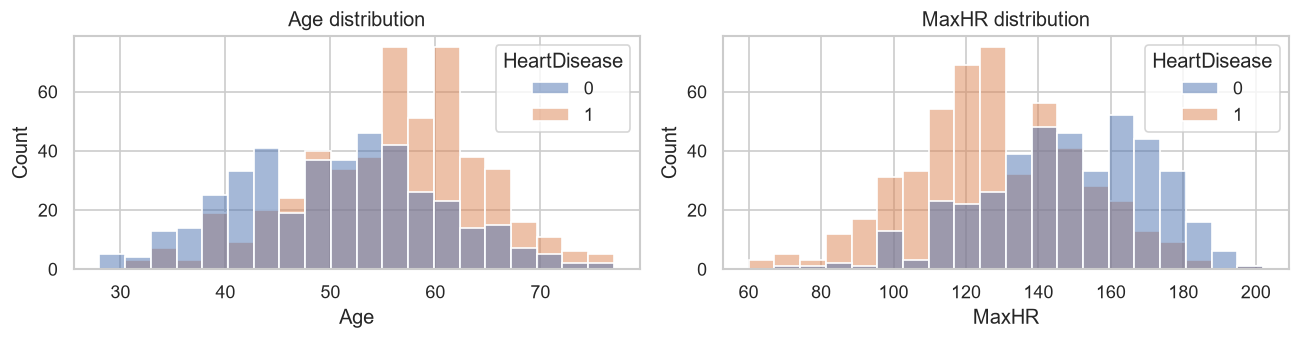

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, column in zip(axes, ['Age', 'MaxHR']):
    sns.histplot(data=data, x=column, hue='HeartDisease', bins=20,
                 alpha=0.5, ax=ax)
    ax.set_title(column + ' distribution')
plt.tight_layout()
plt.show()

Compare the proportion labelled with heart disease for different exercise-angina, chest-pain and ST-slope categories. The percentage is calculated within each category.


ExerciseAngina


,count,percent
ExerciseAngina,,
N,547,35.1
Y,371,85.2


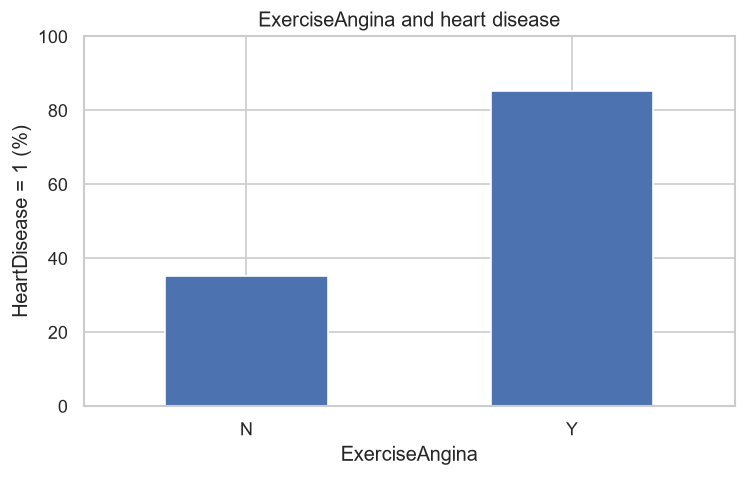


ChestPainType


,count,percent
ChestPainType,,
ASY,496,79.0
ATA,173,13.9
NAP,203,35.5
TA,46,43.5


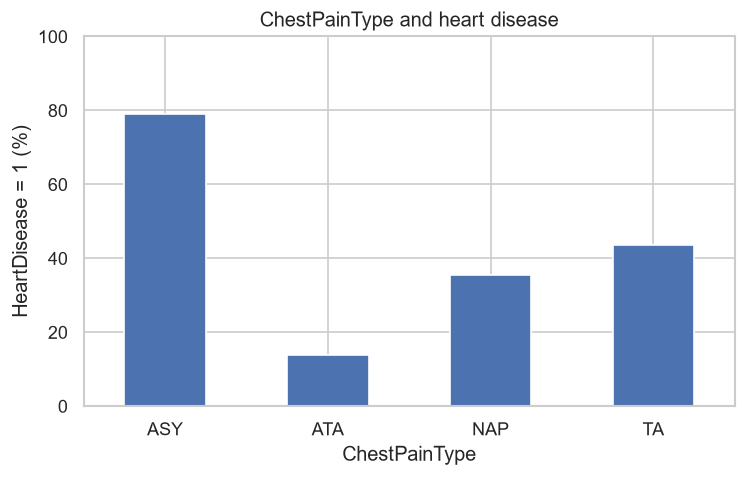


ST_Slope


,count,percent
ST_Slope,,
Down,63,77.8
Flat,460,82.8
Up,395,19.7


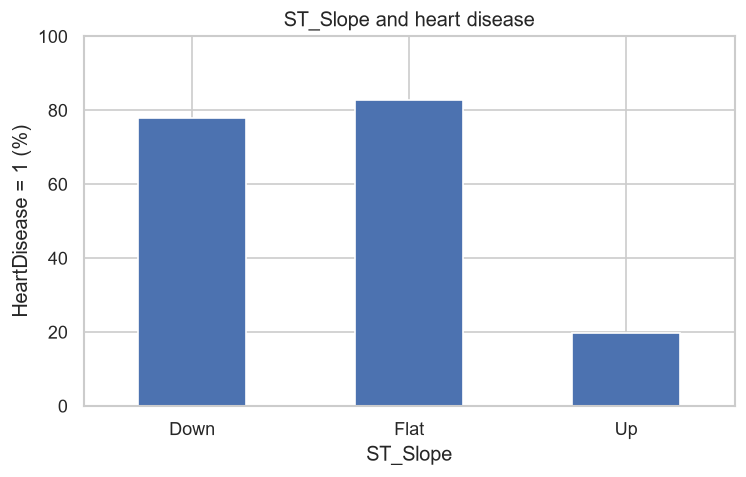

In [8]:
for column in ['ExerciseAngina', 'ChestPainType', 'ST_Slope']:
    summary = data.groupby(column)['HeartDisease'].agg(['count', 'mean'])
    summary['percent'] = (summary['mean'] * 100).round(1)
    print()
    print(column)
    display(summary[['count', 'percent']])
    summary['percent'].plot(kind='bar', title=column + ' and heart disease', ylabel='HeartDisease = 1 (%)', ylim=(0, 100))
    plt.xticks(rotation=0)
    plt.show()

A correlation heatmap gives a quick overview of the **numeric** columns. It excludes cholesterol because many readings are missing. `HeartDisease` and `FastingBS` are recorded as 0/1. Positive numbers mean the variables tend to increase together; negative numbers mean one tends to decrease as the other increases. Correlation does not prove cause.

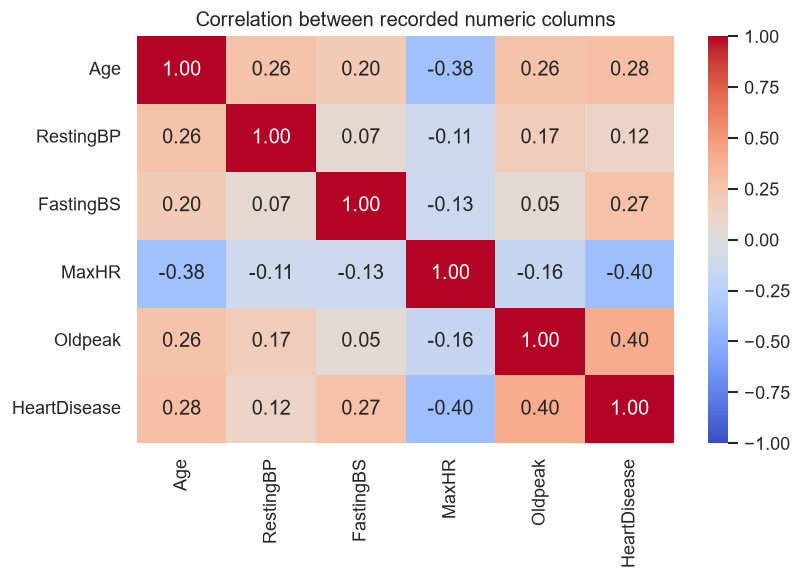

In [9]:
numeric_columns = ['Age', 'RestingBP', 'FastingBS', 'MaxHR',
                   'Oldpeak', 'HeartDisease']
plt.figure(figsize=(7, 5))
sns.heatmap(data[numeric_columns].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation between recorded numeric columns')
plt.tight_layout()
plt.show()

### Other attributes and the heart-disease label rate

`Sex`, `RestingECG` and `FastingBS` were not in the plots above. The same percentage-within-category view is used here.


Sex


,count,percent
Sex,,
F,193,25.9
M,725,63.2


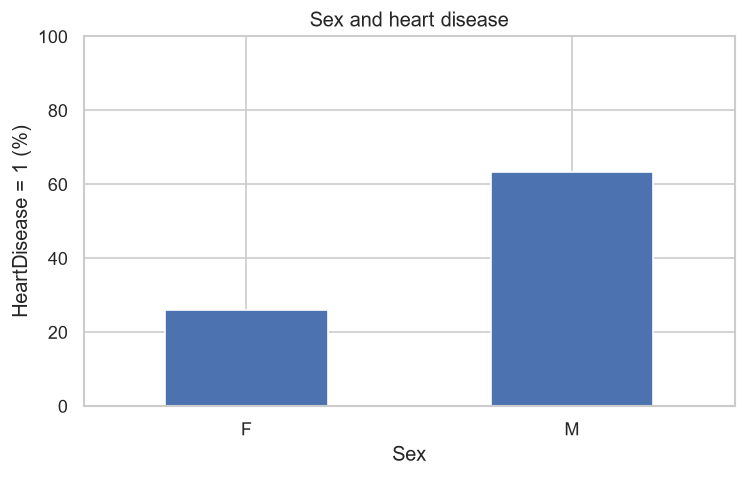


RestingECG


,count,percent
RestingECG,,
LVH,188,56.4
Normal,552,51.6
ST,178,65.7


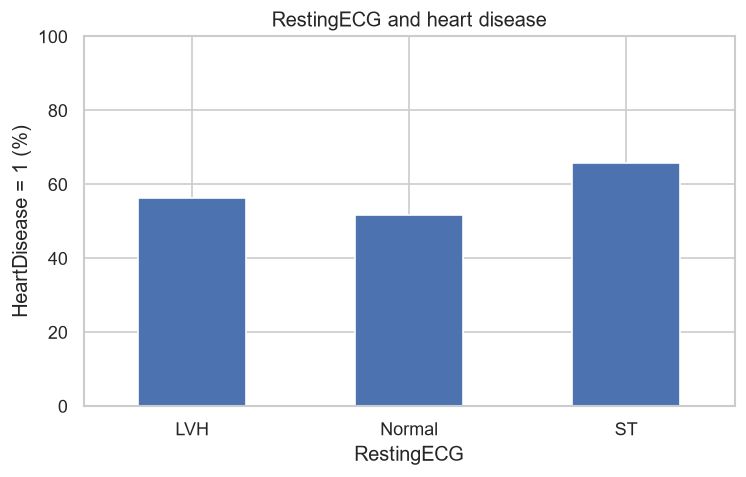


FastingBS


,count,percent
FastingBS,,
0,704,48.0
1,214,79.4


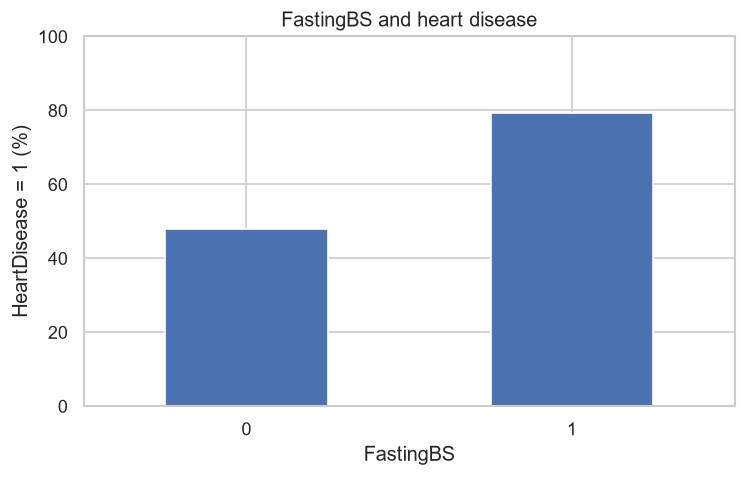

In [10]:
for column in ['Sex', 'RestingECG', 'FastingBS']:
    summary = data.groupby(column)['HeartDisease'].agg(['count', 'mean'])
    summary['percent'] = (summary['mean'] * 100).round(1)
    print()
    print(column)
    display(summary[['count', 'percent']])
    summary['percent'].plot(kind='bar', title=column + ' and heart disease', ylabel='HeartDisease = 1 (%)', ylim=(0, 100))
    plt.xticks(rotation=0)
    plt.show()

The label rate is 63.2% for male records and 25.9% for female records, but 79% of the 918 records are male, so this dataset is not evenly balanced by sex. Records with `FastingBS = 1` have a 79.4% label rate compared with 48.0% for `FastingBS = 0`. Resting ECG shows smaller differences (Normal 51.6%, LVH 56.4%, ST 65.7%).

**EDA findings:** 508 of 918 records have `HeartDisease = 1`. The mean MaxHR is lower in the disease-labelled group (127.66 versus 148.15). The rate of `HeartDisease = 1` is 85.2% among records with exercise-induced angina and 35.1% among those without it. For chest-pain type, ASY is 79.0% and ATA is 13.9%. ST-slope also shows different label rates across categories. The heatmap highlights MaxHR and Oldpeak as numeric variables worth examining, but these are patterns, not evidence of cause.

## 4. Confirmatory data analysis (CDA)

We check five questions suggested by EDA:

- Is `ExerciseAngina` associated with `HeartDisease`? Chi-square test.
- Is `ChestPainType` associated with `HeartDisease`? Chi-square test.
- Is `ST_Slope` associated with `HeartDisease`? Chi-square test.
- Does mean `MaxHR` differ between outcome groups? Two-sided Welch t-test.
- Does mean `Age` differ between outcome groups? Two-sided Welch t-test.

For each question, **H0** says there is no association or mean difference; **H1** says there is one. We use a **5% significance level**: a p-value below 0.05 gives evidence against H0 for that test. These comparisons are exploratory.

### 4.1 Five main statistical tests

The chi-square tests assume independent records and adequate expected cell counts, which are reported below. We use SciPy's continuity correction for the 2-by-2 exercise-angina table; larger tables are uncorrected. Welch tests compare means without assuming equal variances; their t statistic uses label 0 minus label 1. Record independence is assumed and cannot be verified from this CSV. The questions were selected after EDA, so the p-values are exploratory and do not establish independent effects.


In [11]:
alpha = 0.05
test_results = []
for column in ['ExerciseAngina', 'ChestPainType', 'ST_Slope']:
    table = pd.crosstab(data[column], data['HeartDisease'])
    chi2, p_value, dof, expected = chi2_contingency(table, correction=True)
    rates = data.groupby(column)['HeartDisease'].mean() * 100
    comparison = (str(rates.idxmax()) + ': ' + str(round(rates.max(), 1)) +
                  '% vs ' + str(rates.idxmin()) + ': ' +
                  str(round(rates.min(), 1)) + '%')
    test_results.append([column, 'Chi-square', comparison, p_value])
    print()
    print(column)
    display(table)
    print('Chi-square:', round(chi2, 2), 'df:', dof)
    print('p-value:', p_value)
    print('Smallest expected count:', round(expected.min(), 1))
    print('p-value below 0.05:', p_value < alpha)


ExerciseAngina


HeartDisease,0,1
ExerciseAngina,,
N,355,192
Y,55,316


Chi-square: 222.26 df: 1
p-value: 2.907808387659878e-50
Smallest expected count: 165.7
p-value below 0.05: True

ChestPainType


HeartDisease,0,1
ChestPainType,,
ASY,104,392
ATA,149,24
NAP,131,72
TA,26,20


Chi-square: 268.07 df: 3
p-value: 8.08372842808765e-58
Smallest expected count: 20.5
p-value below 0.05: True

ST_Slope


HeartDisease,0,1
ST_Slope,,
Down,14,49
Flat,79,381
Up,317,78


Chi-square: 355.92 df: 2
p-value: 5.167637689470128e-78
Smallest expected count: 28.1
p-value below 0.05: True


In [12]:
for column in ['MaxHR', 'Age']:
    group_0 = data[data['HeartDisease'] == 0][column]
    group_1 = data[data['HeartDisease'] == 1][column]
    t_stat, p_value = ttest_ind(group_0, group_1, equal_var=False)
    comparison = ('label 1: ' + str(round(group_1.mean(), 2)) +
                  ' vs label 0: ' + str(round(group_0.mean(), 2)))
    test_results.append([column, 'Welch t-test', comparison, p_value])
    print()
    print(column)
    print('Mean, label 0:', round(group_0.mean(), 2))
    print('Mean, label 1:', round(group_1.mean(), 2))
    print('t statistic:', round(t_stat, 2))
    print('p-value:', p_value)
    print('p-value below 0.05:', p_value < alpha)


MaxHR
Mean, label 0: 148.15
Mean, label 1: 127.66
t statistic: 13.23
p-value: 1.4306374887872695e-36
p-value below 0.05: True



Age
Mean, label 0: 50.55
Mean, label 1: 55.9
t statistic: -8.82
p-value: 6.348336655825792e-18
p-value below 0.05: True


#### Results at a glance

The observed comparisons describe the group patterns. Each p-value measures how incompatible the corresponding result is with its null hypothesis under the test assumptions.


In [13]:
results = pd.DataFrame(test_results,
                       columns=['Attribute', 'Test', 'Observed comparison', 'p-value'])
results['p-value'] = results['p-value'].map(lambda p: f'{p:.2e}')
display(results)

,Attribute,Test,Observed comparison,p-value
0,ExerciseAngina,Chi-square,Y: 85.2% vs N: 35.1%,2.91e-50
1,ChestPainType,Chi-square,ASY: 79.0% vs ATA: 13.9%,8.08e-58
2,ST_Slope,Chi-square,Flat: 82.8% vs Up: 19.7%,5.17e-78
3,MaxHR,Welch t-test,label 1: 127.66 vs label 0: 148.15,1.43e-36
4,Age,Welch t-test,label 1: 55.9 vs label 0: 50.55,6.35e-18


**CDA findings:** Exercise angina, chest-pain type and ST-slope each show an association with the outcome label. The mean MaxHR and mean age differ between the label groups. All five p-values are below 0.05. These are exploratory statistical associations in this dataset; they do not show that any attribute causes heart disease, and `HeartDisease` does not specifically mean a heart attack.

### 4.2 Cholesterol missingness and the outcome label

This separate data-quality check tests H0: cholesterol missingness and `HeartDisease` are independent, against H1: they are associated. It uses the cleaned data and `chi2_contingency` directly. The 2-by-2 table uses the continuity correction, with a significance level of 0.05. This is a test of recording availability, not cholesterol concentrations.


In [14]:
missing_table = pd.crosstab(
    data['HeartDisease'], data['Cholesterol'].isna(),
    rownames=['HeartDisease'], colnames=['Cholesterol missing']
)
display(missing_table)
missing_chi2, missing_p, missing_dof, missing_expected = chi2_contingency(
    missing_table, correction=True
)
print('Chi-square:', round(missing_chi2, 2), 'df:', missing_dof)
print('p-value:', missing_p)
print('Smallest expected count:', round(missing_expected.min(), 1))
print('p-value below 0.05:', missing_p < 0.05)


Cholesterol missing,False,True
HeartDisease,,
0,390,20
1,356,152


Chi-square: 91.82 df: 1
p-value: 9.504752634875948e-22
Smallest expected count: 76.8
p-value below 0.05: True


Cholesterol is missing in 20 of 410 label-0 records (4.9%) and 152 of 508 label-1 records (29.9%). The chi-square statistic is 91.82 with 1 degree of freedom (p = 9.50e-22), providing evidence against independence. This is a data-quality limitation: the measured subset may not represent all records. The test does not explain why the readings are missing or establish an association between cholesterol concentrations and heart disease. We leave these values missing and do not fill them using the outcome label.


## 5. Conclusion

The three main chi-square tests support associations between the recorded outcome and exercise angina, chest-pain type and ST-slope. The two Welch tests find differences in mean MaxHR and mean age between outcome groups. All five p-values are below 0.05, but these exploratory, one-attribute-at-a-time comparisons do not establish causes or independent effects.

EDA also describes Oldpeak, sex, fasting blood sugar and resting ECG patterns. Cholesterol is missing in 172 records, unevenly across the outcome groups; the separate missingness test supports this concern. The measured cholesterol summaries describe only 746 records, so we draw no conclusion about cholesterol for the full dataset. We assume independent records and cannot infer population prevalence from this combined sample. This project is for data analysis practice, not medical diagnosis.

**Dataset source:** F. Soriano, [Heart Failure Prediction Dataset](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction), Kaggle. The supplied CSV matches its 918-row, 12-column schema. The raw CSV is unchanged.
